# Building Defect AI Notebook workflow

Run from the repository root. Expected data layout: `dataset/BD3_split/{train,val,test}/<class_name>/...`.

**Task:** classify images into the seven BD3 labels. This notebook records the method, why it is used, the result and its interpretation. Do not treat model predictions as professional inspection findings.

In [3]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader

from PIL import Image

# Automatically detect project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    ROOT = CURRENT_DIR.parent
else:
    ROOT = CURRENT_DIR

# Project paths
DATA = ROOT / "dataset" / "BD3_split"
MODEL_PATH = ROOT / "models" / "building_defect_resnet18_experiment3.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", ROOT)
print("Dataset:", DATA)
print("Device:", DEVICE)

assert DATA.exists(), f"Dataset not found: {DATA}"

print("Project paths verified successfully.")

Project root: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI
Dataset: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI\dataset\BD3_split
Device: cuda
Project paths verified successfully.


## 1. ResNet18 preprocessing

The pretrained ResNet18 weights provide their recommended transforms. These resize/crop and normalise images to the distribution expected by the ImageNet-pretrained backbone. Consistent preprocessing at training and inference is essential.

In [4]:
weights = models.ResNet18_Weights.DEFAULT
transform = weights.transforms()
train_ds = datasets.ImageFolder(DATA / "train", transform=transform)
loader = torch.utils.data.DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
images, labels = next(iter(loader))
print("Image batch:", images.shape)  # [batch, channels, height, width]
print("Label batch:", labels.shape)  # [batch]
print("First label:", train_ds.classes[labels[0].item()])


Image batch: torch.Size([16, 3, 224, 224])
Label batch: torch.Size([16])
First label: plain


## 2. Inspect a preprocessed image

Normalisation changes displayed pixel values. For a quick visual check, display the original PIL image from the dataset rather than plotting the normalised tensor directly.

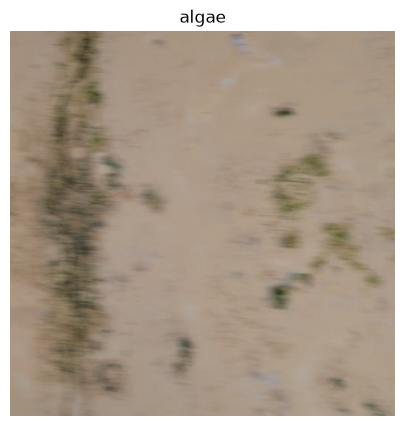

In [5]:
from PIL import Image
path, label = train_ds.samples[0]
img = Image.open(path).convert("RGB")
plt.figure(figsize=(5,5)); plt.imshow(img); plt.title(train_ds.classes[label]); plt.axis("off"); plt.show()


## 3. Why batches?

A batch groups multiple images into one tensor so the GPU can process them efficiently. With batch size 16 and ResNet18 input size 224Ã—224, the expected tensor shape is `[16, 3, 224, 224]` (the final batch may be smaller).